# 8 · Knowledge-graph visualization  (per article)

Draws the KG produced by the pipeline for one article in two forms — a **static** matplotlib/networkx
figure (`results/<id>/kg_<id>.png`) and an **interactive** self-contained pyvis HTML
(`results/<id>/kg_<id>.html`) you can drag, zoom, and hover.

The loader **auto-detects** the graph shape from the file named in `REL_FILES`:

- **Binary** (`relations_ext*.json`, nb7) — entities as nodes, `subject → property → object` triples
  as edges. Nodes coloured by **entity type**; edges **solid** for schema.org properties, **dashed**
  for minted `ex:` properties.
- **Reified / event-centric** (`reified_graph.json`, nb6b) — the **hubs** (Event / Observation /
  Claim) become **★ star nodes** coloured by hub kind, with **main events outlined**; each **role**
  is an edge hub→participant labelled with the role and **dashed when the role was invented**
  (`role_source:"new"`). `cause`/`partOf` roles that point at another hub form the backbone;
  `value_text`-only roles show as small box literals (toggle `INCLUDE_LITERALS`); any leftover
  `binary_relations` render as plain entity→entity edges.

Switch views by editing `REL_FILES` in the config cell — everything below works unchanged for both.

In [ ]:
# --- Config -------------------------------------------------------------------------------
from pathlib import Path

RESULTS_DIR = Path("results")     # per-article outputs from nb7 (binary) or nb6b (reified)
ARTICLE_ID  = "art1"              # which article to draw

# Which graph file to read. The loader AUTO-DETECTS the shape:
#   - reified_graph.json (nb6b)  -> hubs + roles + binary_relations   [event-centric view]
#   - relations_ext*.json (nb7)  -> flat subject/property/object triples [binary view]
# List them in priority order; the first that exists per article wins.
#   binary:   REL_FILES = ["relations_ext_consolidated.json", "relations_ext.json"]
#   reified:  REL_FILES = ["reified_graph.json"]
REL_FILES = ["reified_graph.json"]
# REL_FILES = ["relations_ext_consolidated.json", "relations_ext.json"]

INCLUDE_ISOLATED = True          # False: only entities that take part in >=1 edge (clearer graph)
INCLUDE_LITERALS = True          # reified only: draw value_text-only roles as small box nodes
                                 #   (False -> such roles are dropped; hubs stay less cluttered)
MAX_TYPE_COLORS  = 8              # distinct type colours; rarer types fold into a neutral "Other"
SHOW_EDGE_LABELS = True           # draw the property/role name on each edge in the STATIC figure
STATIC_FIGSIZE   = (16, 11)
LAYOUT_SEED      = 42             # reproducible spring layout

# Interactive (pyvis) readability knobs — bump these if labels look small when zoomed out.
NODE_FONT_SIZE   = 40            # node label size (px)
EDGE_FONT_SIZE   = 30            # edge (property) label size (px)
PYVIS_SPRING     = 150           # spring length — larger = more spread out
PYVIS_HEIGHT     = "900px"       # canvas height

def rel_path(aid):
    for name in REL_FILES:
        p = RESULTS_DIR / aid / name
        if p.exists():
            return p
    return None

print("article:", ARTICLE_ID, "| reads first present of:", REL_FILES)

article: art1 | reads first present of: ['relations_ext_consolidated.json', 'relations_ext.json']


In [46]:
# First run only.
%pip install -q networkx matplotlib pyvis

Note: you may need to restart the kernel to use updated packages.


## 1. Load the graph (self-contained from nb7's relations file)

In [47]:
import json
from collections import Counter

def load_binary(data, cards, include_isolated):
    """nb7 flat relations -> (nodes, edges).  Original behaviour, unchanged."""
    edges = []
    for r in data.get("relations", []):
        edges.append({
            "s": r.get("subject_id"), "o": r.get("object_id"),
            "s_text": r.get("subject_text"), "o_text": r.get("object_text"),
            "s_type": r.get("subject_type"), "o_type": r.get("object_type"),
            "property": r.get("property"), "source": r.get("property_source"),
            "phrases": r.get("relation_phrases", []),
            "evidence": (r.get("evidence") or [None])[0],
            "confidence": r.get("confidence"),
        })
    nodes = {}
    def _node(eid, ft=None, fy=None):
        c = cards.get(eid, {})
        nodes[eid] = {"label": c.get("text") or ft or eid, "type": c.get("type") or fy or "Unknown"}
    for e in edges:
        _node(e["s"], e["s_text"], e["s_type"]); _node(e["o"], e["o_text"], e["o_type"])
    used = {e["s"] for e in edges} | {e["o"] for e in edges}
    if include_isolated:
        for eid in cards:
            if eid not in nodes: _node(eid)
    else:
        nodes = {i: v for i, v in nodes.items() if i in used}
    return nodes, edges

def load_reified(data, cards, include_isolated):
    """nb6b reified_graph.json -> (nodes, edges) for the SAME renderers.
       Hubs become star nodes (type = hub_kind: Event/Observation/Claim); every role becomes an
       edge hub->participant labelled with the role and DASHED when the role was invented
       (role_source == 'new'). value_ref_hub gives hub->hub backbone edges (cause / partOf);
       value_text-only roles become small box 'literal' nodes when INCLUDE_LITERALS. The
       binary_relations (stable entity<->entity facts) render as plain entity->entity edges,
       solid for schema.org properties and dashed for minted ex: ones (like the binary graph)."""
    nodes, edges = {}, []

    def ent(eid):                                                  # lazily add a referenced entity node
        if eid and eid not in nodes:
            c = cards.get(eid, {})
            nodes[eid] = {"label": c.get("text") or eid, "type": c.get("type") or "Unknown"}
        return eid

    for h in data.get("hubs", []):                                # 1) all hubs first, so value_ref_hub targets exist
        nodes[h["id"]] = {"label": h.get("label") or h["id"], "type": h.get("hub_kind") or "Hub",
                          "is_hub": True, "shape": "star",
                          "hub_kind": h.get("hub_kind"), "hub_type": h.get("type"),
                          "is_main": bool(h.get("is_main")),
                          "evidence": (h.get("evidence") or [None])[0]}

    lit = 0
    for h in data.get("hubs", []):                                # 2) roles -> edges
        hid = h["id"]; ev = (h.get("evidence") or [None])[0]
        for r in h.get("roles", []):
            role   = r.get("role") or ""
            source = "ex" if r.get("role_source") == "new" else "schema.org"   # dashed iff invented
            if r.get("value_ref"):
                o = ent(r["value_ref"])
            elif r.get("value_ref_hub"):
                o = r["value_ref_hub"]
                if o not in nodes:                                 # dangling ref -> stub hub
                    nodes[o] = {"label": o, "type": "Hub", "is_hub": True, "shape": "star"}
            elif r.get("value_text") is not None and INCLUDE_LITERALS:
                lit += 1; o = f"{hid}~L{lit}"
                nodes[o] = {"label": str(r["value_text"]), "type": "Literal", "is_lit": True, "shape": "box"}
            else:
                continue
            edges.append({"s": hid, "o": o, "property": role, "source": source,
                          "phrases": [], "evidence": ev, "confidence": h.get("confidence"),
                          "s_text": None, "o_text": r.get("value_text"), "s_type": None, "o_type": None})

    for b in data.get("binary_relations", []):                    # 3) stable binary (hybrid) facts
        s = ent(b.get("subject_id")); o = ent(b.get("object_id"))
        evb = b.get("evidence")
        psrc = "schema.org" if b.get("property_source", "schema.org") == "schema.org" else "ex"
        edges.append({"s": s, "o": o, "property": b.get("property"), "source": psrc,
                      "phrases": [], "evidence": (evb[0] if isinstance(evb, list) else evb),
                      "confidence": None, "s_text": None, "o_text": None, "s_type": None, "o_type": None})

    if include_isolated:                                          # 4) unreferenced entities
        for eid in cards: ent(eid)
    else:
        used = {e["s"] for e in edges} | {e["o"] for e in edges}
        nodes = {i: v for i, v in nodes.items() if v.get("is_hub") or i in used}
    return nodes, edges

def load_kg(aid, include_isolated=INCLUDE_ISOLATED):
    """Auto-detect the file shape (reified hubs vs nb7 binary triples) and return (nodes, edges, name)."""
    p = rel_path(aid)
    assert p is not None, f"no graph file for {aid} (expected one of {REL_FILES} under results/{aid}/)"
    data  = json.loads(p.read_text())
    cards = {e["id"]: e for e in data.get("entities", [])}          # id -> {id,text,type,aliases}
    nodes, edges = (load_reified if "hubs" in data else load_binary)(data, cards, include_isolated)
    return nodes, edges, str(p.name)

nodes, edges, src = load_kg(ARTICLE_ID)
type_counts = Counter(n["type"] for n in nodes.values())
src_counts  = Counter(e["source"] for e in edges)
n_hubs = sum(1 for n in nodes.values() if n.get("is_hub"))
n_bin  = len(json.loads(rel_path(ARTICLE_ID).read_text()).get("binary_relations", [])) if n_hubs else 0
label  = f"{len(nodes)} nodes ({n_hubs} hubs), {len(edges)} edges ({n_bin} binary" + ")" if n_hubs else f"{len(nodes)} nodes, {len(edges)} edges"
print(f"{ARTICLE_ID}: {label}  (from {src})")
print("  node types:", dict(type_counts.most_common(10)), ("..." if len(type_counts) > 10 else ""))
print("  edge sources:", dict(src_counts), "" if not n_hubs else " (ex -> dashed: invented role or minted binary property)")

art1: 103 nodes, 95 edges  (from relations_ext_consolidated.json)
  node types: {'Duration': 9, 'DefinedRegion': 9, 'Country': 7, 'City': 6, 'GovernmentOrganization': 6, 'QuantitativeValue': 4, 'Percentage': 4, 'WeatherServiceOrganization': 4, 'DayOfWeek': 4, 'GovernmentOfficial': 3} ...
  edge sources: {'vocab': 59, 'schema.org': 36} 


## 2. Colour map — entity type → colour (fixed order, rarer types → "Other")

In [48]:
# Categorical palette (validated, colourblind-checked). Hues are assigned to the MOST FREQUENT types
# in fixed order and never cycled; every rarer type folds into a single neutral "Other" — so identity
# stays legible instead of dissolving into near-duplicate hues.
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
OTHER_COLOR   = "#9a998f"     # neutral gray for folded-in types
SCHEMA_EDGE   = "#5b5a54"     # schema.org edges (solid)
EX_EDGE       = "#b06a2c"     # minted ex: edges (dashed)
SURFACE       = "#fcfcfb"
INK           = "#0b0b0b"

def build_type_colors(nodes, max_colors=MAX_TYPE_COLORS):
    ranked = [t for t, _ in Counter(n["type"] for n in nodes.values()).most_common()]
    top    = ranked[:max_colors]
    cmap   = {t: PALETTE[i] for i, t in enumerate(top)}
    return cmap, (len(ranked) > len(top))

TYPE_COLORS, HAS_OTHER = build_type_colors(nodes)
def node_color(t):  return TYPE_COLORS.get(t, OTHER_COLOR)
def edge_color(src): return SCHEMA_EDGE if src == "schema.org" else EX_EDGE

print("type -> colour")
for t, c in TYPE_COLORS.items():
    print(f"  {c}  {t}  (x{type_counts[t]})")
if HAS_OTHER:
    n_other = sum(v for t, v in type_counts.items() if t not in TYPE_COLORS)
    print(f"  {OTHER_COLOR}  Other  ({len(type_counts) - len(TYPE_COLORS)} types, {n_other} nodes)")
print("edges: solid = schema.org, dashed = ex: (minted)")

type -> colour
  #2a78d6  Duration  (x9)
  #1baf7a  DefinedRegion  (x9)
  #eda100  Country  (x7)
  #008300  City  (x6)
  #4a3aa7  GovernmentOrganization  (x6)
  #e34948  QuantitativeValue  (x4)
  #e87ba4  Percentage  (x4)
  #eb6834  WeatherServiceOrganization  (x4)
  #9a998f  Other  (38 types, 54 nodes)
edges: solid = schema.org, dashed = ex: (minted)


## 3. Static figure (matplotlib + networkx) → `results/<id>/kg_<id>.png`

saved results/art1/kg_art1.png


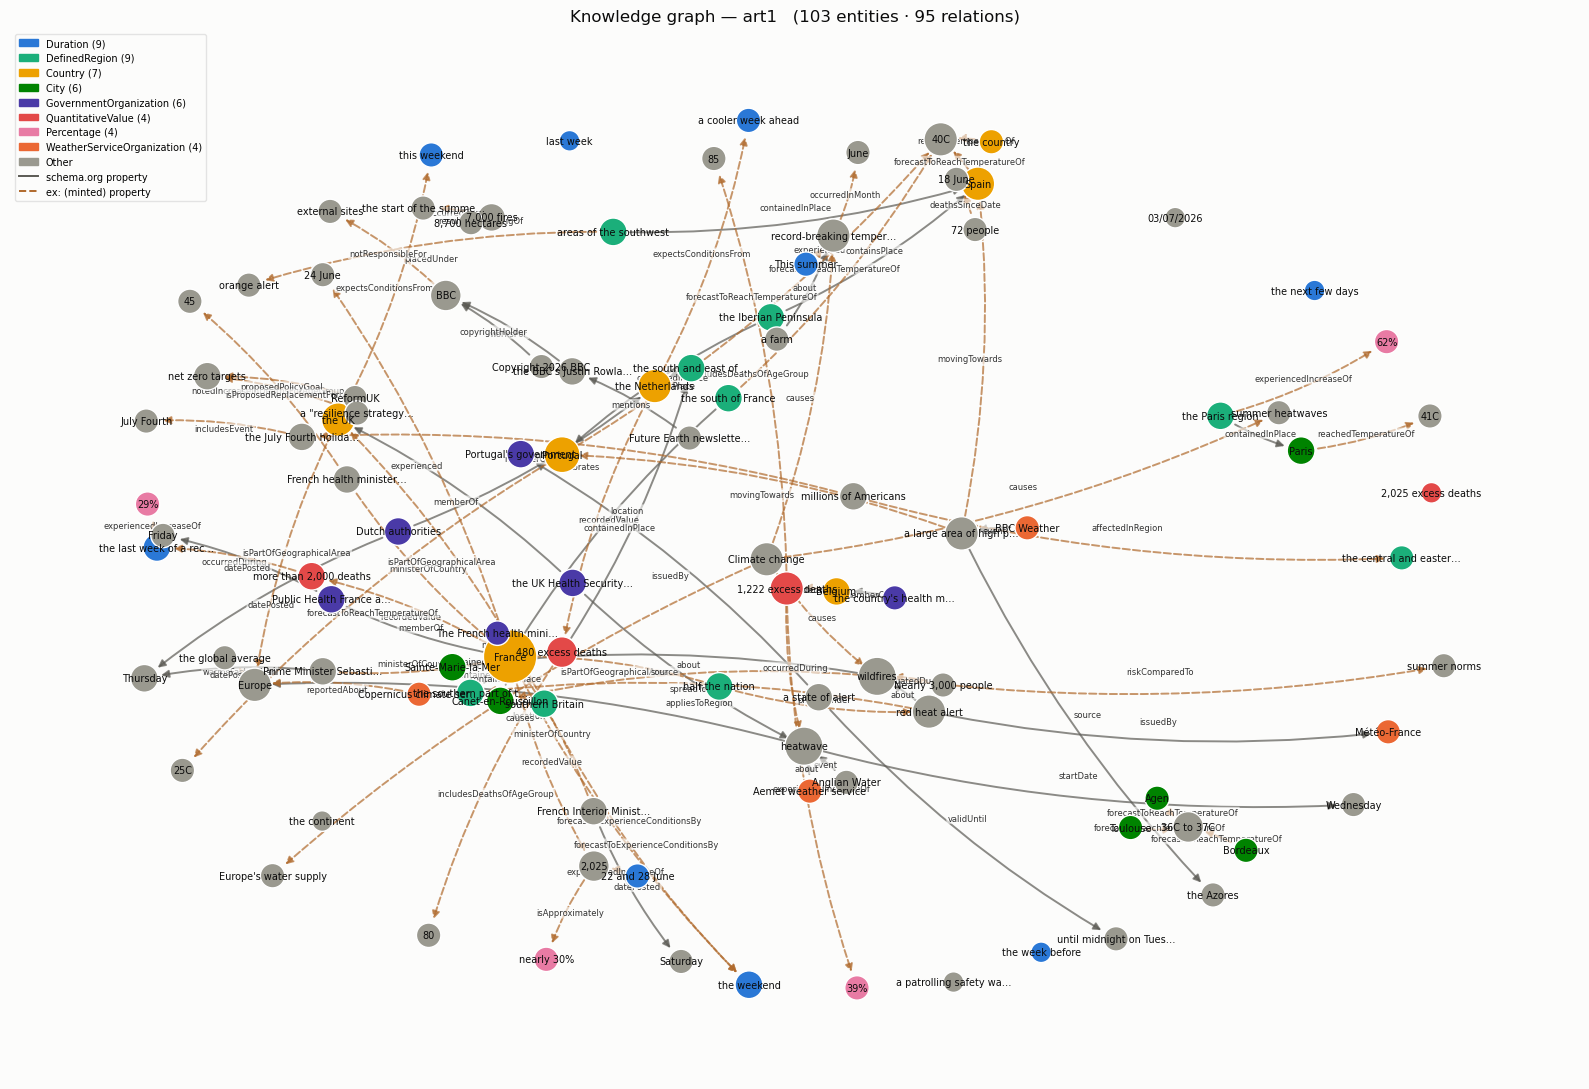

In [49]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

def kg_stem(aid, nodes):
    """Output basename: reified graphs (have hub nodes) get a `_reified` suffix so they sit
       alongside the binary `kg_<id>` files instead of overwriting them."""
    return f"kg_{aid}_reified" if any(n.get("is_hub") for n in nodes.values()) else f"kg_{aid}"

def draw_static(aid, nodes, edges, show_edge_labels=SHOW_EDGE_LABELS, save=True, show=True):
    G = nx.MultiDiGraph()
    for i, n in nodes.items():
        G.add_node(i, **n)
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            G.add_edge(e["s"], e["o"], property=e["property"], source=e["source"])

    deg = dict(G.degree())
    pos = nx.spring_layout(G, seed=LAYOUT_SEED, k=1.6 / max(len(G) ** 0.5, 1))
    n_hubs = sum(1 for i in nodes if nodes[i].get("is_hub"))

    fig, ax = plt.subplots(figsize=STATIC_FIGSIZE)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE); ax.axis("off")

    # nodes grouped by kind so hubs (star) and literals (square) get their own marker & size
    def kind(i):
        n = nodes[i]
        return "hub" if n.get("is_hub") else ("lit" if n.get("is_lit") else "ent")
    for grp, marker, base in (("ent", "o", 220), ("hub", "*", 700), ("lit", "s", 150)):
        ids = [i for i in G.nodes() if kind(i) == grp]
        if not ids:
            continue
        nx.draw_networkx_nodes(
            G, pos, ax=ax, nodelist=ids, node_shape=marker,
            node_color=[node_color(nodes[i]["type"]) for i in ids],
            node_size=[base + 90 * deg.get(i, 0) for i in ids],
            edgecolors=[INK if nodes[i].get("is_main") else "white" for i in ids],
            linewidths=[2.2 if nodes[i].get("is_main") else 1.0 for i in ids])

    for src_kind, dashed in (("schema.org", False), ("ex", True)):
        elist = [(u, v) for u, v, d in G.edges(data=True)
                 if (d.get("source") == "schema.org") == (src_kind == "schema.org")]
        if elist:
            nx.draw_networkx_edges(
                G, pos, ax=ax, edgelist=elist,
                edge_color=(SCHEMA_EDGE if src_kind == "schema.org" else EX_EDGE),
                style=("dashed" if dashed else "solid"),
                width=1.4, alpha=0.7, arrows=True, arrowsize=11,
                connectionstyle="arc3,rad=0.08", node_size=600)

    nx.draw_networkx_labels(
        G, pos, ax=ax, font_size=7, font_color=INK,
        labels={i: (nodes[i]["label"][:22] + ("…" if len(nodes[i]["label"]) > 22 else "")) for i in G.nodes()})

    if show_edge_labels:
        agg = {}                                                   # aggregate parallel edges' labels per (u,v)
        for u, v, d in G.edges(data=True):
            agg.setdefault((u, v), []).append(d.get("property") or "")
        nx.draw_networkx_edge_labels(
            G, pos, ax=ax, font_size=6, font_color="#333333", rotate=False,
            bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.6),
            edge_labels={k: ", ".join(dict.fromkeys(v)) for k, v in agg.items()})

    handles = [mpatches.Patch(color=c, label=f"{t} ({type_counts[t]})") for t, c in TYPE_COLORS.items()]
    if HAS_OTHER:
        handles.append(mpatches.Patch(color=OTHER_COLOR, label="Other"))
    if n_hubs:                                                     # reified: role-edge + hub-marker legend
        handles += [plt.Line2D([0], [0], color=SCHEMA_EDGE, lw=1.4, label="seed / schema.org role"),
                    plt.Line2D([0], [0], color=EX_EDGE, lw=1.4, ls="--", label="invented (new) role"),
                    plt.Line2D([0], [0], marker="*", color="none", markerfacecolor="#555",
                               markersize=13, label="hub (★, outlined = main)")]
        subtitle = f"{n_hubs} hubs · {len(nodes) - n_hubs} nodes · {len(edges)} role/relation edges"
    else:                                                          # binary: original legend
        handles += [plt.Line2D([0], [0], color=SCHEMA_EDGE, lw=1.4, label="schema.org property"),
                    plt.Line2D([0], [0], color=EX_EDGE, lw=1.4, ls="--", label="ex: (minted) property")]
        subtitle = f"{len(nodes)} entities · {len(edges)} relations"
    ax.legend(handles=handles, loc="upper left", fontsize=7, frameon=True,
              facecolor=SURFACE, edgecolor="#dddddd")
    ax.set_title(f"Knowledge graph — {aid}   ({subtitle})", fontsize=12, color=INK)
    fig.tight_layout()

    if save:
        out = RESULTS_DIR / aid / f"{kg_stem(aid, nodes)}.png"
        fig.savefig(out, dpi=150, facecolor=SURFACE, bbox_inches="tight")
        print("saved", out)
    if show:
        plt.show()
    else:
        plt.close(fig)

draw_static(ARTICLE_ID, nodes, edges)

## 4. Interactive figure (pyvis) → `results/<id>/kg_<id>.html`

Drag nodes, zoom, and hover — node tooltip shows its type + aliases, edge tooltip shows the property,
its source, the originating relation phrase(s), and the evidence span. The HTML is **self-contained**
(vis.js inlined), so it opens offline.

In [50]:
FREEZE_AFTER_STABILIZE = True     # let physics settle once on open, then stop moving (freeze layout)

def draw_interactive(aid, nodes, edges, save=True, show=True):
    try:
        from pyvis.network import Network
    except ImportError:
        print("pyvis not installed — run the %pip cell above (the static PNG above still works).")
        return None
    # count degree for node sizing
    deg = Counter()
    for e in edges:
        if e["s"] in nodes and e["o"] in nodes:
            deg[e["s"]] += 1; deg[e["o"]] += 1

    try:
        net = Network(height=PYVIS_HEIGHT, width="100%", directed=True,
                      bgcolor=SURFACE, font_color=INK, cdn_resources="in_line", notebook=True)
    except TypeError:                                              # older pyvis without some kwargs
        net = Network(height=PYVIS_HEIGHT, width="100%", directed=True, bgcolor=SURFACE, font_color=INK)
    # Big, high-contrast labels (white halo so they read over edges), roomier layout, hover + nav buttons.
    # set_options wants a JSON string; json.dumps guarantees valid JSON (pyvis strips whitespace itself).
    net.set_options(json.dumps({
        "nodes": {"shape": "dot",
                  "font": {"size": NODE_FONT_SIZE, "face": "arial", "color": INK,
                           "strokeWidth": 4, "strokeColor": SURFACE}},
        "edges": {"arrows": {"to": {"enabled": True, "scaleFactor": 0.6}},
                  "color": {"inherit": False, "opacity": 0.8},
                  "smooth": {"enabled": True, "type": "dynamic"},
                  "font": {"size": EDGE_FONT_SIZE, "face": "arial", "color": "#333333",
                           "strokeWidth": 5, "strokeColor": SURFACE, "align": "middle"},
                  "width": 1.5},
        "physics": {"barnesHut": {"gravitationalConstant": -32000, "centralGravity": 0.2,
                                  "springLength": PYVIS_SPRING, "springConstant": 0.02,
                                  "damping": 0.5, "avoidOverlap": 0.7},
                    "minVelocity": 0.75, "stabilization": {"enabled": True, "iterations": 400, "fit": True}},
        "interaction": {"hover": True, "tooltipDelay": 120, "navigationButtons": True, "keyboard": True},
    }))

    for i, n in nodes.items():
        if n.get("is_hub"):                                        # hub -> big star; main events outlined
            title = f'{n["label"]}  ·  {n.get("hub_kind")} / {n.get("hub_type")}'
            if n.get("is_main"): title += "  ·  MAIN"
            if n.get("evidence"): title += f'\nevidence: {n["evidence"]}'
            net.add_node(i, label=n["label"], title=title, color=node_color(n["type"]),
                         shape="star", size=26 + 4 * deg.get(i, 0),
                         borderWidth=(5 if n.get("is_main") else 2),
                         borderWidthSelected=6)
        elif n.get("is_lit"):                                      # literal value -> small box
            net.add_node(i, label=n["label"], title=n["label"], color="#e9e7df",
                         shape="box", size=10)
        else:                                                      # entity -> dot (as before)
            net.add_node(i, label=n["label"], title=f'{n["label"]}  ·  type: {n["type"]}',
                         color=node_color(n["type"]), shape="dot", size=14 + 5 * deg.get(i, 0))
    for e in edges:
        if e["s"] not in nodes or e["o"] not in nodes:
            continue
        tip = f'{e["property"]}  [{e["source"]}]'
        if e["phrases"]:  tip += f'\nphrase(s): {", ".join(e["phrases"])}'
        if e["evidence"]: tip += f'\nevidence: {e["evidence"]}'
        net.add_edge(e["s"], e["o"], label=e["property"] or "", title=tip,
                     color=edge_color(e["source"]), dashes=(e["source"] != "schema.org"),
                     arrows="to")

    out = RESULTS_DIR / aid / f"{kg_stem(aid, nodes)}.html"
    if save:
        try:
            net.write_html(str(out), notebook=False)              # newer pyvis
        except Exception:
            net.save_graph(str(out))
        if FREEZE_AFTER_STABILIZE:
            # Inject a snippet so the graph settles once on open, then turns physics OFF and holds
            # that layout (nodes stay draggable, but nothing drifts). The setTimeout is a fallback in
            # case the stabilization event has already fired by the time this script runs.
            freeze = (
                '\n<script type="text/javascript">\n'
                '  (function () {\n'
                '    if (typeof network === "undefined") return;\n'
                '    var stop = function () { network.setOptions({ physics: false }); };\n'
                '    network.on("stabilizationIterationsDone", stop);\n'
                '    setTimeout(stop, 4000);\n'
                '  })();\n'
                '</script>\n'
            )
            html = out.read_text()
            out.write_text(html.replace("</body>", freeze + "</body>", 1) if "</body>" in html
                           else html + freeze)
        print("saved", out)
    if show:
        from IPython.display import IFrame, display
        display(IFrame(src=str(out), width="100%", height="780px"))
    return out

draw_interactive(ARTICLE_ID, nodes, edges)

saved results/art1/kg_art1.html


PosixPath('results/art1/kg_art1.html')

## 5. Triples table (subject → property → object)

In [51]:
# Plain, sorted listing of every edge — the KG as text, for a quick read / copy.
def print_triples(nodes, edges):
    rows = sorted(edges, key=lambda e: (e.get("property") or "", nodes.get(e["s"], {}).get("label", "")))
    print(f"{len(rows)} relations\n" + "-" * 90)
    for e in rows:
        s = nodes.get(e["s"], {}).get("label", e.get("s_text") or e["s"])
        o = nodes.get(e["o"], {}).get("label", e.get("o_text") or e["o"])
        tag = "schema" if e["source"] == "schema.org" else "ex:"
        conf = f'  ({e["confidence"]})' if e.get("confidence") is not None else ""
        print(f'  {s}  --{e["property"]} [{tag}]-->  {o}{conf}')

print_triples(nodes, edges)

95 relations
------------------------------------------------------------------------------------------
  Aemet weather service  --about [schema]-->  heatwave  (1.0)
  a farm  --about [schema]-->  record-breaking temperatures  (1.0)
  red heat alert  --about [schema]-->  wildfires  (1.0)
  the UK Health Security Agency  --about [schema]-->  heatwave  (0.9)
  millions of Americans  --affectedInRegion [ex:]-->  the central and eastern US  (1.0)
  red heat alert  --appliesToRegion [ex:]-->  the southern part of the country  (1.0)
  Climate change  --causes [ex:]-->  record-breaking temperatures  (1.0)
  Climate change  --causes [ex:]-->  summer heatwaves  (1.0)
  Climate change  --causes [ex:]-->  Europe's water supply  (1.0)
  Climate change  --causes [ex:]-->  wildfires  (1.0)
  millions of Americans  --celebrates [ex:]-->  the July Fourth holiday weekend  (1.0)
  Canet-en-Roussillon  --containedInPlace [schema]-->  France  (0.9)
  Sainte-Marie-la-Mer  --containedInPlace [schema]-->  Fr

## 6. Batch — render every article

In [52]:
# Render the static PNG (and interactive HTML) for every article that has an nb7 relations file.
# No inline display — just writes results/<id>/kg_<id>.png and .html.
_articles = sorted({p.parent.name for name in REL_FILES for p in RESULTS_DIR.glob(f"*/{name}")})
print("rendering", len(_articles), "article(s):", _articles)
for aid in _articles:
    n, e, _ = load_kg(aid)
    if not n:
        print(f"  {aid}: no connected entities, skipped"); continue
    # rebuild the per-article type colour map so each figure is self-consistent
    global TYPE_COLORS, HAS_OTHER, type_counts
    type_counts = Counter(v["type"] for v in n.values())
    TYPE_COLORS, HAS_OTHER = build_type_colors(n)
    draw_static(aid, n, e, save=True, show=False)
    draw_interactive(aid, n, e, save=True, show=False)
print("done")

rendering 4 article(s): ['art1', 'art2', 'art4', 'art5']
saved results/art1/kg_art1.png
saved results/art1/kg_art1.html
saved results/art2/kg_art2.png
saved results/art2/kg_art2.html
saved results/art4/kg_art4.png
saved results/art4/kg_art4.html
saved results/art5/kg_art5.png
saved results/art5/kg_art5.html
done
